In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn import metrics
import numpy as np
import altair as alt
import seaborn as sns
import matplotlib.pyplot as plt
alt.renderers.enable('notebook')
alt.data_transformers.disable_max_rows()
pd.set_option("display.max_rows", 999)

In [2]:
def auc_accuracy(df):
    #df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
    labels = df.peptide_detected.to_numpy()
    for col in df.columns[df.columns.str.match('ANN_s')]:
        scores = df[col].to_numpy()
        predictions = (scores >= 0.5)
        # AUC
        fpr, tpr, thresholds = metrics.roc_curve(labels, scores)
        auc = metrics.auc(fpr, tpr)
        # Accuracy
        weights = abs(labels - (labels.sum() / labels.shape[0]))
        acc = ((predictions == labels) * weights).sum() / weights.sum()
        # Precision
        precision = (predictions & labels).sum() / labels.sum()
        # PPV
        #all_true = df.peptide_detected.sum()
        #ppv = df.sort_values(col, ascending=False).iloc[:all_true].peptide_detected.sum() / all_true
        
        if 'shuffle' in col:
            seqtype = 'shuffle'
        else:
            seqtype = 'original'
        ix = col.split('_')[-1]
        
        yield seqtype, ix, auc, acc, precision

In [3]:
%%time
metrics_df = pd.DataFrame(columns=['dataset', 'peplen', 'seqtype', 'ix', 'metric', 'value'])
for dataset in ['HumanBLCL', 'HumanB721', 'HumanPBMCs', 'MouseCT26', 'MouseEL4']:
    dfs = []
    for p in ['9']:#['8', '9', '10', '11', 'all']:
        print(dataset, p)
        if p == 'all':
            df = pd.concat(dfs, copy=False)
        else:
            df = pd.read_csv('output/old/finalTables/reduced/%s_%s_NetMHC-4.0.tsv' % (dataset, p), sep='\t', index_col=0)
            dfs.append(df)
        for seqtype, ix, auc, acc, precision in auc_accuracy(df):
            metrics_df.loc[metrics_df.shape[0]] = [dataset, p, seqtype, ix, 'AUC', auc]
            metrics_df.loc[metrics_df.shape[0]] = [dataset, p, seqtype, ix, 'Accuracy', acc]
            metrics_df.loc[metrics_df.shape[0]] = [dataset, p, seqtype, ix, 'Precision', precision]

HumanBLCL 9
HumanB721 9
HumanPBMCs 9
MouseCT26 9
MouseEL4 9
CPU times: user 43.5 s, sys: 2.58 s, total: 46.1 s
Wall time: 47.7 s


In [35]:
#metrics_df.to_csv('all_metrics.tsv', sep='\t')
metrics_df = pd.read_csv('all_metrics.tsv', sep='\t')

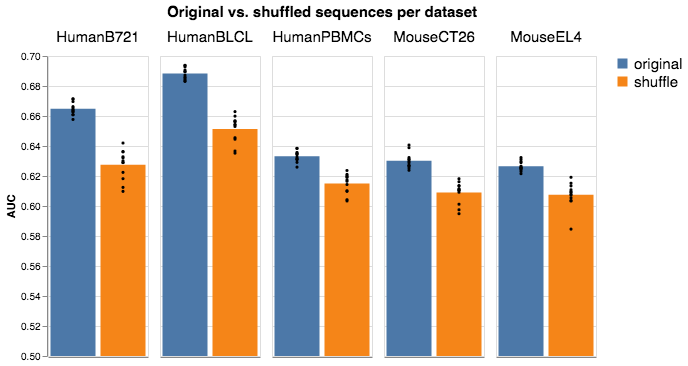

In [177]:
df = metrics_df[(metrics_df.metric == 'AUC') & (metrics_df.peplen == 'all')]

bar = alt.Chart().mark_bar().encode(#.mark_tick(color='red', thickness=5, size=40).encode(
    x=alt.X('seqtype:O', title=None, axis=alt.Axis(values=[0], ticks=True, grid=False, labels=False)),
    y=alt.Y('mean(value):Q', title='AUC', scale=alt.Scale(domain=[0.5,0.7])),
    color=alt.Color('seqtype:N', legend=alt.Legend(title=None, labelFontSize=15))
).properties(width=100)

scatter = alt.Chart().mark_circle(color='black', opacity=1, size=10).encode(
    x='seqtype:O',
    y='value:Q'
)

alt.layer(bar, scatter, data=df).facet(
    column=alt.Column(
        'dataset:N',
        header=alt.Header(
            title='Original vs. shuffled sequences per dataset',
            titleFontSize=15,
            labelFontSize=15,
            labelAngle=0,
            titleOrient='top',
            labelOrient='top',
            labelAlign='center',
            labelPadding=10,
            titlePadding=0
        )
    ),
).transform_calculate(
    # Generate Gaussian jitter with a Box-Muller transform
    jitter='sqrt(-2*log(random()))*cos(2*PI*random())'  # useless
).configure_facet(
    spacing=10
)#.configure_view(
#    stroke=None
#)

In [110]:
# df = metrics_df[(metrics_df.metric == 'AUC') & (metrics_df.peplen == 'all')]
# bars = alt.Chart().mark_bar().encode(
#     x='seqtype:O',
#     y='mean(value):Q',
#     color='seqtype:N'
# ).properties(width=100)

# error_bars = alt.Chart().mark_errorbar(extent='ci').encode(
#     x='seqtype:O',
#     y='value:Q'
# )

# alt.layer(bars, error_bars, data=df).facet(
#     column='dataset:N'
# )

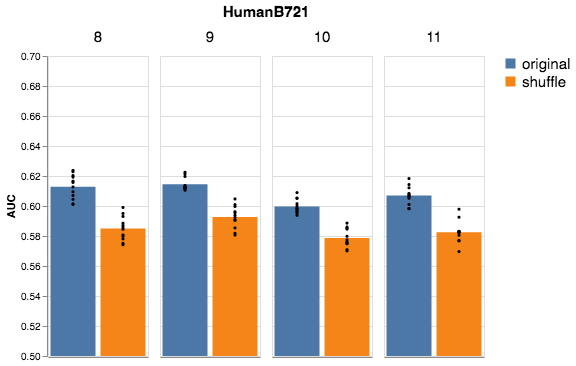

In [25]:
for dataset in ['HumanB721', 'HumanBLCL', 'HumanPBMCs', 'MouseCT26', 'MouseEL4']:
    df = metrics_df[(metrics_df.dataset == dataset) & (metrics_df.metric == 'AUC') & (metrics_df.peplen != 'all')]

    bar = alt.Chart().mark_bar().encode(
        x=alt.X('seqtype:O', title=None, axis=alt.Axis(values=[0], ticks=True, grid=False, labels=False)),
        y=alt.Y('mean(value):Q', title='AUC', scale=alt.Scale(domain=[0.5,0.7])),
        color=alt.Color('seqtype:N', legend=alt.Legend(title=None, labelFontSize=15))
    ).properties(width=100)

    scatter = alt.Chart().mark_circle(color='black', opacity=1, size=10).encode(
        x='seqtype:O',
        y='value:Q'
    )

    alt.layer(bar, scatter, data=df).facet(
    column=alt.Column(
        'peplen:N',
        sort=['8', '9', '10', '11'],
        header=alt.Header(
            #title='AUC of original vs. shuffled sequences per peptide size',
            title=dataset,
            titleFontSize=15,
            labelFontSize=15,
            labelAngle=0,
            titleOrient='top',
            labelOrient='top',
            labelAlign='center',
            labelPadding=10,
            titlePadding=0
        )
    )
    ).configure_facet(
        spacing=10
    ).display()

In [15]:
masked = pd.read_csv('output/various/metrics.tsv', sep='\t', header=[0,1], index_col=0, skipinitialspace=False)
mm = masked.AUC.drop(['Adagrad', 'Adam'], axis=1).melt()
mm['seqtype'] = mm.variable.str.contains('shuffle').replace(False, 'original').replace(True, 'shuffle')

In [23]:
df = mm

bar = alt.Chart().mark_bar().encode(
    x='variable:O',
    y=alt.Y('mean(value):Q', title='AUC', scale=alt.Scale(domain=[0.5,0.7])),
    color=alt.Color('seqtype:N', legend=alt.Legend(title=None, labelFontSize=15))
).properties(width=500)

scatter = alt.Chart().mark_circle(color='black', opacity=1, size=10).encode(
    x='variable:O',
    y='value:Q'
)

#alt.layer(bar, scatter, data=df).display()
bar

SchemaValidationError: Invalid specification

        altair.vegalite.v3.api.Chart, validating 'required'

        'data' is a required property
        

alt.Chart(...)